# New wd=0.1 benchmark variant — exploratory follow-up
Prepared for execution, not independently scientifically certified. Original historical prose is background, not current evidence.
No new test access or adjacency edits. MB22 trains five models at wd=0.1 (not historical wd=0.01).
K32 and other training differences mean the single-vs-SEL comparison does not isolate training-code quality.
MB23 is a first-seed circuit analysis; its threshold verdicts are exploratory, not proof of a unique algorithm.


# MB23 — Do the Two-Token Models Use Attention? From Behaviour to Circuits (Book 2 of 2)

**Track B · Follow-up to MB22 · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | When the previous event's information sits one position back and the player has no global identity (MB22), does the model use its attention heads to bring identity and context together, and what do the identity and context circuits look like? |
| **Models** | `two_token_anon` (main, first seed), compared with `two_token_id` and `single` from MB22, and with SEL-4L's results (MB14–MB19). |
| **Population** | P-player validation conflicts (same events as MB04–MB21), split into the discovery and estimation halves used throughout. Identity analyses use the events whose player appears earlier in the window ("linked" events). |
| **Status** | Exploratory follow-up; not part of the MB12 lock. The plan, with every reading rule, is written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB23_plan.json`, `results/MB23_*`, `figures/MB23_*` |

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)
import itertools
from math import factorial
from matplotlib.patches import FancyArrowPatch
import mi_src.twotoken_followup as tt
importlib.reload(tt)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


<module 'mi_src.twotoken_followup' from '/content/soccer_mi/.mi_analysis_rerun/src/twotoken_followup.py'>

In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 109 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


## 1. The sub-questions and the edits

Every edit acts on one P-player conflict event at position p of its window (its context token c_p), and is defined the same way for all three designs, so the models can be compared.

| Behaviour | Edit | Sub-question |
|---|---|---|
| **Identity** | the player at c_p gets a label (or, with a global identity, the index) that links it to nothing else: the model no longer knows which earlier events are this player's | RQ2 / RQ4: how the player's identity reaches the decision |
| **Previous event** | the previous event's action, outcome and end zone are replaced by those of a donor event (another conflict, another match). Two-token models: in a_(p−1); `single`: in c_p's history fields | RQ3 / RQ5: how "what just happened" reaches the decision |
| **Current situation** | c_p's situation fields (zone, coordinates, period, minute, score, possession state, time gap) take the donor event's values | RQ3 / RQ5 |
| **Interaction** | identity effect with the own previous event minus identity effect with the donor's previous event | RQ7: where identity and context meet |

## 2. The plan (written before any number)

In [4]:
MAIN_SEED = int(os.environ.get("TT_MAIN_SEED", os.environ.get("TT_SEEDS", "0").split(",")[0]))

In [5]:
PLAN = {
    "status": "follow-up after MB22; exploratory",
    "models": {"main": f"two_token_anon seed {MAIN_SEED}", "comparisons": [f"two_token_id seed {MAIN_SEED}", f"single seed {MAIN_SEED}", "SEL-4L (results of MB14-MB19)"]},
    "behaviours": ["identity (link broken)", "previous event (donor's)", "current situation (donor's)", "interaction"],
    "linked_rule": "identity analyses use events whose player has at least one earlier event in the window",
    "attention_reading": "share of attention from c_p to each token group, minus the share a uniform causal pattern would give",
    "subsets": "all subsets of the heads and MLPs (2**12 for the 4-layer, 2-head model) (complement mean-ablated at every position); chosen on discovery, scored on estimation",
    "attention_used_rule": ("attention is called USED for a behaviour if all heads with no MLP keep F >= 0.3 OR the 4 MLPs with no head keep F <= 0.7 "
                            "(estimation half), i.e. the heads carry a substantial share that SEL-4L's heads did not (compare against regenerated MB14 outputs; historical values are not this benchmark)"),
    "edges": "path patching of every sender -> receiver edge at c_p on discovery; keep q < 0.05 and |R| >= 0.05; prune to input-to-logit paths; re-measure on estimation",
    "circuit_verdict": "MEANINGFUL if F >= 0.5, F above the 95th percentile of 100 random sets with the same numbers of heads and MLPs (not testable when only one such set exists), >= 70 per cent of edges replicate, and not the whole model; PARTIAL if F and replication pass; otherwise NOT ESTABLISHED"
}
plan_path = OUT / "config" / "MB23_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB23_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB23_plan.json
{
 "status": "follow-up after MB22; exploratory",
 "models": {
  "main": "two_token_anon seed 0",
  "comparisons": [
   "two_token_id seed 0",
   "single seed 0",
   "SEL-4L (results of MB14-MB19)"
  ]
 },
 "behaviours": [
  "identity (link broken)",
  "previous event (donor's)",
  "current situation (donor's)",
  "interaction"
 ],
 "linked_rule": "identity analyses use events whose player has at least one earlier event in the window",
 "attention_reading": "share of attention from c_p to each token group, minus the share a uniform causal pattern would give",
 "subsets": "all subsets of the heads and MLPs (2**12 for the 4-layer, 2-head model) (complement mean-ablated at every position); chosen on discovery, scored on estimation",
 "attention_used_rule": "attention is called USED for a behaviour if all heads with no MLP keep F >= 0.3 OR the 4 MLPs with no head keep F <= 0.7 (estimation half), i.e. the heads carry a substantial share that SEL-4L's heads did n

## 3. Models, population and edits

In [6]:
TT_DIR = OUT / "artifacts" / "twotoken"
SIZES = {name: int(tensor.max().item()) + 1 for name, tensor in bundle["encoded"].tensors.items() if not tensor.is_floating_point()}


def load_tt(variant, seed):
    run_dir = TT_DIR / f"{variant}_s{seed}"
    if not (run_dir / "best.pt").exists():
        return None
    config = tt.Config.from_dict(json.loads((run_dir / "config.json").read_text()))
    model = tt.TwoTokenModel(config).to(DEVICE)
    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=DEVICE))
    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    return model


MODELS = {name: load_tt(name, MAIN_SEED) for name in ["two_token_anon", "two_token_id", "single"]}
MODELS = {k: v for k, v in MODELS.items() if v is not None}
assert "two_token_anon" in MODELS, "BLOCKED: run MB22 first (no two_token_anon checkpoint)."
MAIN = MODELS["two_token_anon"]
K_EVENTS = MAIN.config.n_events
TT_DATA = tt.EventData(events, bundle["encoded"].tensors, bundle["targets"], n_events=K_EVENTS)
scored = pd.DataFrame(TT_DATA.scored["val"])
units = p_player[["event_row", "match_id", "half", "a_ctx", "a_id", "player", "genuine"]].merge(scored, on="event_row")
rows = TT_DATA.windows["val"][units["window"].to_numpy()]
players = TT_DATA.features["player"][rows]
units["linked"] = [bool((players[i, :p] == players[i, p]).any()) for i, p in enumerate(units["position"])]
units = units[units["position"] >= 1].reset_index(drop=True)
rng = np.random.default_rng(0)
donor = []
for _, row in units.iterrows():
    pool = units[(units.match_id != row.match_id) & (units.half == row.half)]
    assert len(pool), "BLOCKED: no same-half donor from another match"
    donor.append(pool.index[rng.integers(len(pool))])
units["donor"] = donor
print(f"P-player conflicts mapped to {K_EVENTS}-event windows: {len(units)} | linked (player appears earlier): {units['linked'].mean():.3f} | "
      f"discovery {int((units.half == 'discovery').sum())}, estimation {int((units.half == 'estimation').sum())}")
from src.model import FACTOR_GROUPS as _FG, CONTINUOUS_GROUPS as _CG
SITUATION = [f for g in ["space", "time", "state"] for f in _FG[g]] + [f for g in ["space", "time"] for f in _CG.get(g, [])]


def get_inputs(model, table):
    inputs, _ = tt.eval_batch(TT_DATA, "val", table["window"].to_numpy(), DEVICE, model.config.n_slots)
    return inputs


def edit(model, inputs, table, kind, donor_inputs=None, donor_table=None):
    """Return edited inputs. kind: 'identity', 'previous', 'situation'."""
    new = {k: v.clone() for k, v in inputs.items()}
    b = torch.arange(len(table), device=DEVICE)
    p = torch.as_tensor(table["position"].to_numpy(), device=DEVICE)
    if kind == "identity":
        if model.config.variant == "two_token_anon":
            used = new["slot"]
            fresh = torch.tensor([int(np.setdiff1d(np.arange(1, model.config.n_slots), used[i].cpu().numpy())[0]) for i in range(len(table))], device=DEVICE)
            new["slot"][b, p] = fresh
        else:
            new["player"][b, p] = 0
        return new
    dp = torch.as_tensor(donor_table["position"].to_numpy(), device=DEVICE)
    if kind == "previous":
        if model.config.two_token:
            for f in tt.ACTION_FIELDS:
                new[f"act_{f}"][b, p - 1] = donor_inputs[f"act_{f}"][b, dp - 1]
        else:
            for f in tt.HISTORY_FEATURES:
                new[f][b, p] = donor_inputs[f][b, dp]
        return new
    for f in SITUATION:
        new[f][b, p] = donor_inputs[f][b, dp]
    return new


def delta_at(model, inputs, table, replace=None):
    logits, _ = tt.forward(model, inputs, replace=replace)
    c = tt.context_index(model, torch.as_tensor(table["position"].to_numpy(), device=DEVICE))
    at = logits[torch.arange(len(table), device=DEVICE), c]
    return mi_metrics.delta(at, torch.as_tensor(table["a_ctx"].to_numpy(), device=DEVICE), torch.as_tensor(table["a_id"].to_numpy(), device=DEVICE))


RUNS = {"clean": [], "identity": ["identity"], "previous": ["previous"], "situation": ["situation"], "previous+identity": ["previous", "identity"]}


def run_inputs(model, table):
    """{run name: inputs} for one batch of units."""
    inputs = get_inputs(model, table)
    donor_table = units.loc[table["donor"].to_numpy()].reset_index(drop=True)
    donor_inputs = get_inputs(model, donor_table)
    out = {}
    for name, kinds in RUNS.items():
        x = inputs
        for kind in kinds:
            x = edit(model, x, table, kind, donor_inputs, donor_table)
        out[name] = x
    return out


BEHAVIOURS = {"identity": (["clean", "identity"], [1]), "previous event": (["clean", "previous"], [1]),
              "current situation": (["clean", "situation"], [1]),
              "interaction": (["clean", "identity", "previous", "previous+identity"], [1, -1, -1, 1])}


def behaviour_value(values, name):
    """values: {run: Delta array}. Identity-type behaviours are clean - edited; interaction is the 2x2 contrast."""
    runs, signs = BEHAVIOURS[name]
    if name == "interaction":
        return values["clean"] - values["identity"] - values["previous"] + values["previous+identity"]
    return values[runs[0]] - values[runs[1]]

P-player conflicts mapped to 32-event windows: 1744 | linked (player appears earlier): 0.657 | discovery 1215, estimation 529


## 4. Behaviour: does the decision still favour context, and how big is each effect?

In [7]:
@torch.no_grad()
def all_runs(model, table, replace_builder=None):
    out = {name: np.zeros(len(table)) for name in RUNS}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part].reset_index(drop=True)
        inputs = run_inputs(model, chunk)
        for name, x in inputs.items():
            replace = replace_builder(x, chunk) if replace_builder else None
            out[name][part] = delta_at(model, x, chunk, replace)
    return out


behaviour_rows = []
BASE_VALUES = {}
for model_name, model in MODELS.items():
    values = all_runs(model, units)
    BASE_VALUES[model_name] = values
    for half in ["estimation", "discovery"]:
        keep = (units.half == half).to_numpy()
        m = units["match_id"].to_numpy()
        c1 = mi_metrics.summarise(values["clean"][keep], m[keep], N_BOOT)
        row = {"model": model_name, "half": half, "n": c1["n"], "mean Delta": c1["mean"], "share Delta > 0": float((values["clean"][keep] > 0).mean())}
        for name in BEHAVIOURS:
            k = keep & (units["linked"].to_numpy() if name in ["identity", "interaction"] else True)
            effect = behaviour_value(values, name)[k]
            s = mi_metrics.summarise(effect, m[k], N_BOOT)
            row[f"{name}: mean"], row[f"{name}: mean |.|"], row[f"{name}: CI"] = s["mean"], float(np.abs(effect).mean()), f"[{s['ci_low']:.3f}, {s['ci_high']:.3f}]"
        behaviour_rows.append(row)
behaviour = pd.DataFrame(behaviour_rows)
behaviour.to_csv(OUT / "results" / "MB23_behaviour.csv", index=False)
print(behaviour.round(4).T.to_string())
print("\nSEL-4L for comparison (MB15, estimation): mean Delta 5.95; identity (player removed) mean |.| 0.47; "
      "whole-context effect mean |.| 6.5; interaction mean |.| 0.60")

                                           0                 1                2                 3                 4                 5
model                         two_token_anon    two_token_anon     two_token_id      two_token_id            single            single
half                              estimation         discovery       estimation         discovery        estimation         discovery
n                                        529              1215              529              1215               529              1215
mean Delta                            5.8409             5.394           5.6932            5.4886            6.0874            6.0501
share Delta > 0                       0.9811            0.9663           0.9698            0.9523            0.9735            0.9786
identity: mean                       -0.0446           -0.0986          -0.1527           -0.2101           -0.5363           -0.3783
identity: mean |.|                    0.4013            0.4231

## 5. Where does the scored context token look?

For each head: the share of attention from c_p to each group of earlier tokens, minus the share a uniform causal pattern would give that group. Groups: c_p itself; the previous action token a_(p−1); the same player's earlier action tokens; the same player's earlier context tokens; all other earlier action tokens; all other earlier context tokens.

group  other action tokens  other context tokens  previous action token  same player: action tokens  same player: context tokens  self (c_p)
head                                                                                                                                        
L0H0                -0.014                -0.032                  0.036                       0.005                        0.002       0.002
L0H1                 0.148                -0.391                  0.251                       0.041                       -0.039      -0.010
L1H0                -0.077                -0.281                  0.303                       0.012                        0.020       0.024
L1H1                -0.093                -0.002                  0.035                      -0.005                        0.023       0.043
L2H0                -0.261                -0.438                  0.750                       0.009                       -0.042      -0.018
L2H1         

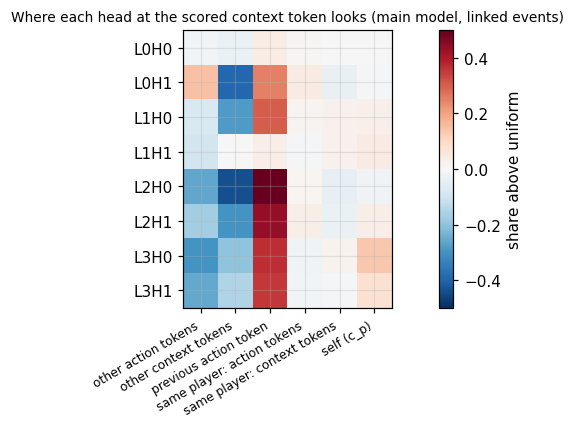

In [8]:
def token_groups(model, inputs, table):
    """{group: bool [B, T]} for each unit."""
    B, T = len(table), model.config.n_tokens
    p = table["position"].to_numpy()
    slots = inputs["slot"].cpu().numpy() if model.config.variant == "two_token_anon" else inputs["player"].cpu().numpy()
    groups = {g: np.zeros((B, T), dtype=bool) for g in ["self (c_p)", "previous action token", "same player: action tokens",
                                                        "same player: context tokens", "other action tokens", "other context tokens"]}
    for i in range(B):
        c = 2 * p[i]
        groups["self (c_p)"][i, c] = True
        groups["previous action token"][i, c - 1] = True
        own = slots[i, p[i]]
        for j in range(p[i]):
            same = own > 0 and slots[i, j] == own
            if 2 * j + 1 != c - 1:
                groups["same player: action tokens" if same else "other action tokens"][i, 2 * j + 1] = True
            groups["same player: context tokens" if same else "other context tokens"][i, 2 * j] = True
    return groups


@torch.no_grad()
def attention_shares(model, table):
    sites = [f"attn_pattern_{l}" for l in range(len(model.blocks))]
    totals = {}
    count = 0
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part].reset_index(drop=True)
        inputs = get_inputs(model, chunk)
        _, cache = tt.forward(model, inputs, capture=sites)
        groups = token_groups(model, inputs, chunk)
        c = torch.as_tensor(2 * chunk["position"].to_numpy(), device=DEVICE)
        b = torch.arange(len(chunk), device=DEVICE)
        for l, site in enumerate(sites):
            pattern = cache[site][b, :, c].cpu().numpy()          # [B, H, T]
            for g, mask in groups.items():
                share = (pattern * mask[:, None, :]).sum(-1)       # [B, H]
                uniform = mask.sum(-1, keepdims=True) / (c.cpu().numpy()[:, None] + 1)
                for h in range(pattern.shape[1]):
                    key = (f"L{l}H{h}", g)
                    totals.setdefault(key, []).append(share[:, h] - uniform[:, 0])
    return pd.DataFrame([{"head": k[0], "group": k[1], "excess attention share": float(np.concatenate(v).mean())} for k, v in totals.items()])


attention = attention_shares(MAIN, units[units.linked].reset_index(drop=True))
attention.to_csv(OUT / "results" / "MB23_attention.csv", index=False)
table_att = attention.pivot(index="head", columns="group", values="excess attention share")
print(table_att.round(3).to_string())
fig, axis = plt.subplots(figsize=(9, 4))
image = axis.imshow(table_att.to_numpy(), cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axis.set_xticks(range(table_att.shape[1])); axis.set_xticklabels(table_att.columns, rotation=30, ha="right", fontsize=8)
axis.set_yticks(range(table_att.shape[0])); axis.set_yticklabels(table_att.index)
plt.colorbar(image, ax=axis, label="share above uniform")
axis.set_title("Where each head at the scored context token looks (main model, linked events)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB23_attention.png", bbox_inches="tight", dpi=150); plt.show()

## 6. Which components carry each behaviour? Every subset of the 12 heads and MLPs

As MB14: a circuit S keeps its heads and MLPs, every other one is mean-ablated at every position (means over 2,000 validation windows, per token position). F(S) = pooled sign-aligned (behaviour under S − behaviour with everything ablated) / (full − everything ablated). Subsets are chosen on discovery and scored on estimation. This is the direct comparison with SEL-4L, whose regenerated results are in MB14.

In [9]:
COMPONENTS = circuits.all_components(len(MAIN.blocks), MAIN.blocks[0].attention.n_heads)
HEADS = [c for c in COMPONENTS if not c.endswith("MLP")]
MLPS = [c for c in COMPONENTS if c.endswith("MLP")]
N_COMP = len(COMPONENTS)
assert N_COMP <= 16, "BLOCKED: too many components for an exhaustive subset search"
MASKS = np.arange(2 ** N_COMP)
FULL, EMPTY = 2 ** N_COMP - 1, 0


@torch.no_grad()
def model_means(model, n_windows=2000):
    sites = [f"{k}_{l}" for l in range(len(model.blocks)) for k in ["head_z", "mlp_out"]]
    windows = np.arange(min(n_windows, len(TT_DATA.windows["val"])))
    totals = {}
    for start in range(0, len(windows), BATCH):
        inputs, _ = tt.eval_batch(TT_DATA, "val", windows[start:start + BATCH], DEVICE, model.config.n_slots)
        _, cache = tt.forward(model, inputs, capture=sites)
        for s in sites:
            totals[s] = cache[s].sum(0) + (totals[s] if s in totals else 0)
    return {s: v / len(windows) for s, v in totals.items()}


MEANS_TT = model_means(MAIN)


def members(mask):
    return [COMPONENTS[i] for i in range(N_COMP) if (mask >> i) & 1]


@torch.no_grad()
def subset_runs(model, means, table, masks):
    out = {name: np.zeros((len(masks), len(table)), dtype=np.float32) for name in RUNS}
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part].reset_index(drop=True)
        inputs = run_inputs(model, chunk)
        for i, mask in enumerate(masks):
            ablated = [c for c in COMPONENTS if c not in members(mask)]
            replace = circuits.ablation_edits(ablated, means, None) if ablated else None
            for name, x in inputs.items():
                out[name][i, part] = delta_at(model, x, chunk, replace)
    return out


start = time.time()
SUB = {half: subset_runs(MAIN, MEANS_TT, units[units.half == half].reset_index(drop=True), MASKS) for half in ["discovery", "estimation"]}
print(f"all {len(MASKS)} subsets scored in {time.time() - start:.0f} s")


def faithfulness(runs, name, keep):
    matrix = behaviour_value(runs, name).astype(np.float64)[:, keep]
    full, empty = matrix[FULL], matrix[EMPTY]
    sign = np.sign(full - empty)
    return ((matrix - empty) * sign).sum(1) / np.abs(full - empty).sum()


def keep_rows(half, name):
    table = units[units.half == half]
    return table["linked"].to_numpy() if name in ["identity", "interaction"] else np.ones(len(table), dtype=bool)


F_TT = {half: {name: faithfulness(SUB[half], name, keep_rows(half, name)) for name in BEHAVIOURS} for half in SUB}
SHAPLEY_W = np.zeros((N_COMP, len(MASKS)))
for i in range(N_COMP):
    for mask in MASKS:
        if mask & (1 << i):
            continue
        s = bin(int(mask)).count("1")
        w = factorial(s) * factorial(N_COMP - s - 1) / factorial(N_COMP)
        SHAPLEY_W[i, mask] -= w; SHAPLEY_W[i, mask | (1 << i)] += w

mask_of = lambda comps: int(sum(1 << COMPONENTS.index(c) for c in comps))
named_rows = []
for name in BEHAVIOURS:
    values = F_TT["estimation"][name]
    phi = SHAPLEY_W @ values
    named_rows.append({"behaviour": name, "F: all heads, no MLP": values[mask_of(HEADS)], "F: all MLPs, no head": values[mask_of(MLPS)],
                       "Shapley share of heads": float(phi[[COMPONENTS.index(h) for h in HEADS]].sum()),
                       "Shapley share of MLPs": float(phi[[COMPONENTS.index(m) for m in MLPS]].sum()),
                       "largest single head (Shapley)": HEADS[int(np.argmax(phi[[COMPONENTS.index(h) for h in HEADS]]))],
                       "attention USED (plan rule)": bool(values[mask_of(HEADS)] >= 0.3 or values[mask_of(MLPS)] <= 0.7)})
named_tt = pd.DataFrame(named_rows)
named_tt.to_csv(OUT / "results" / "MB23_heads_vs_mlps.csv", index=False)
print(named_tt.round(3).to_string(index=False))
print("SEL-4L comparison: use regenerated MB14 results, not historical constants.")
shapley_tt = pd.DataFrame({name: SHAPLEY_W @ F_TT["estimation"][name] for name in BEHAVIOURS}, index=COMPONENTS)
shapley_tt.to_csv(OUT / "results" / "MB23_shapley.csv")
print(shapley_tt.round(3).to_string())

all 4096 subsets scored in 3322 s


        behaviour  F: all heads, no MLP  F: all MLPs, no head  Shapley share of heads  Shapley share of MLPs largest single head (Shapley)  attention USED (plan rule)
         identity                 0.043                 0.512                   0.208                  0.792                          L3H1                        True
   previous event                 0.198                 0.000                   0.546                  0.454                          L3H0                        True
current situation                 0.068                 0.638                   0.199                  0.801                          L3H1                        True
      interaction                 0.049                 0.000                   0.440                  0.560                          L2H1                        True
SEL-4L comparison: use regenerated MB14 results, not historical constants.
       identity  previous event  current situation  interaction
L0H0      0.003           

In [10]:
best_rows = []
for name in BEHAVIOURS:
    sizes = np.array([bin(int(m)).count("1") for m in MASKS])
    for k in range(1, N_COMP + 1):
        cand = np.where(sizes == k)[0]
        chosen = cand[np.argmax(F_TT["discovery"][name][cand])]
        best_rows.append({"behaviour": name, "size": k, "best subset (chosen on discovery)": "+".join(members(chosen)),
                          "F estimation": float(F_TT["estimation"][name][chosen])})
best_tt = pd.DataFrame(best_rows)
best_tt.to_csv(OUT / "results" / "MB23_best_by_size.csv", index=False)
for name in BEHAVIOURS:
    block = best_tt[(best_tt.behaviour == name) & (best_tt["F estimation"] >= 0.8)]
    print(f"{name}: smallest discovery-chosen circuit with estimation F >= 0.8: "
          + (f"size {int(block['size'].min())} -> {block.loc[block['size'].idxmin(), 'best subset (chosen on discovery)']}" if len(block) else "none"))

identity: smallest discovery-chosen circuit with estimation F >= 0.8: size 7 -> L0MLP+L1MLP+L2H0+L2H1+L2MLP+L3H1+L3MLP
previous event: smallest discovery-chosen circuit with estimation F >= 0.8: size 9 -> L0MLP+L1H0+L1MLP+L2H0+L2H1+L2MLP+L3H0+L3H1+L3MLP
current situation: smallest discovery-chosen circuit with estimation F >= 0.8: size 6 -> L0MLP+L1MLP+L2H0+L2MLP+L3H1+L3MLP
interaction: smallest discovery-chosen circuit with estimation F >= 0.8: size 9 -> L0MLP+L1H0+L1MLP+L2H0+L2H1+L2MLP+L3H0+L3H1+L3MLP


## 7. The circuits, edge by edge

Path patching at c_p, as MB19. **Senders:** the input groups at c_p (player label, team, role, competition, space, time, state), the earlier tokens in three groups (previous action token, the same player's earlier tokens, all other earlier tokens; each sent into the key and value inputs of the heads of one layer), every head and every MLP. **Receivers:** every head's query, key and value input, every MLP, the logits. Edges are found on the discovery half (q < 0.05 and |R| ≥ 0.05), pruned to input-to-logit paths, and re-measured on the estimation half.

In [11]:
GROUP_NAMES = list(tt.embed_factors(MAIN, get_inputs(MAIN, units.iloc[:2])).keys())
INPUT_SENDERS = [g for g in GROUP_NAMES if g.startswith("factor_") and not g.startswith("factor_act") and g not in ("factor_type", "factor_position")]
EARLIER = ["previous action token", "same player's earlier tokens", "other earlier tokens"]
L, H = len(MAIN.blocks), MAIN.blocks[0].attention.n_heads
SENDERS = INPUT_SENDERS + [f"{g}>L{l}" for g in EARLIER for l in range(L)] + COMPONENTS
CAPTURE = INPUT_SENDERS + ["resid_pre_0"] + [f"resid_pre_{l}" for l in range(1, L)] + [f"head_z_{l}" for l in range(L)] + [f"mlp_out_{l}" for l in range(L)]


def receivers_for(sender):
    if ">L" in sender:
        layer = int(sender.split(">L")[1])
        return [f"L{layer}H{h}.{s}" for h in range(H) for s in ["k", "v"]]
    if sender.startswith("factor_"):
        layer, is_head = -1, False
    else:
        layer, is_head = circuits.parse(sender)[1], not sender.endswith("MLP")
    out = []
    for later in range(L):
        if later > layer:
            out += [f"L{later}H{h}.{s}" for h in range(H) for s in ["q", "k", "v"]]
        if later > layer or (later == layer and is_head):
            out.append(f"L{later}MLP")
    return out + ["logits"]


EDGES = [(s, r) for s in SENDERS for r in receivers_for(s)]
print(f"senders {len(SENDERS)} | edges {len(EDGES)}")


def earlier_mask(model, inputs, chunk, group):
    groups = token_groups(model, inputs, chunk)
    if group == "previous action token":
        mask = groups["previous action token"]
    elif group == "same player's earlier tokens":
        mask = groups["same player: action tokens"] | groups["same player: context tokens"]
    else:
        mask = groups["other action tokens"] | groups["other context tokens"]
    return torch.as_tensor(mask, device=DEVICE)


def difference(sender, clean, corrupt, c, masks):
    if ">L" in sender:
        group, layer = sender.split(">L")
        site = "resid_pre_0" if layer == "0" else f"resid_pre_{layer}"
        return (clean[site] - corrupt[site]) * masks[group][..., None]
    return circuits.only_at(circuits.sender_difference(MAIN, clean, corrupt, sender), c)


@torch.no_grad()
def patch_edges(table, name, edges):
    runs, signs = BEHAVIOURS[name]
    pairs = [(1, "clean", "identity")] if name == "identity" else [(1, "clean", "previous")] if name == "previous event" else \
        [(1, "clean", "situation")] if name == "current situation" else [(1, "clean", "previous"), (-1, "identity", "previous+identity")]
    clean_m, corrupt_m = np.zeros(len(table)), np.zeros(len(table))
    patched = np.zeros((len(edges), len(table)))
    for part in mi_setup.batch_slices(len(table), BATCH):
        chunk = table.iloc[part].reset_index(drop=True)
        inputs = run_inputs(MAIN, chunk)
        c = tt.context_index(MAIN, torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE))
        a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE); a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
        b = torch.arange(len(chunk), device=DEVICE)
        d = lambda logits: mi_metrics.delta(logits[b, c], a_ctx, a_id)
        masks = {g: earlier_mask(MAIN, inputs["clean"], chunk, g) for g in EARLIER}
        for weight, clean_name, corrupt_name in pairs:
            clean_logits, clean_cache = tt.forward(MAIN, inputs[clean_name], capture=CAPTURE)
            corrupt_logits, corrupt_cache = tt.forward(MAIN, inputs[corrupt_name], capture=CAPTURE)
            cv = d(corrupt_logits)
            clean_m[part] += weight * d(clean_logits); corrupt_m[part] += weight * cv
            diffs = {}
            for i, (sender, receiver) in enumerate(edges):
                if sender not in diffs:
                    diffs[sender] = difference(sender, clean_cache, corrupt_cache, c, masks)
                diff = diffs[sender]
                if not torch.any(diff != 0):
                    patched[i, part] += weight * cv
                    continue
                logits, _ = tt.forward(MAIN, inputs[corrupt_name], replace={circuits.receiver_site(receiver): hooks.add_at(diff)})
                patched[i, part] += weight * d(logits)
    return clean_m, corrupt_m, patched


def edge_stats(table, clean, corrupt, patched, edges):
    m = table["match_id"].to_numpy()
    out = []
    for i, (s, r) in enumerate(edges):
        res = mi_metrics.pooled_recovery(patched[i] - corrupt, clean - corrupt, m, N_BOOT)
        aligned = mi_metrics.aligned(patched[i] - corrupt, clean - corrupt)
        p = 1.0 if np.allclose(aligned, 0) else mi_metrics.bootstrap_pvalue(aligned, m, N_BOOT)
        out.append({"sender": s, "receiver": r, "R": res["recovery"], "CI low": res["ci_low"], "CI high": res["ci_high"], "p": p})
    frame = pd.DataFrame(out)
    frame["q"] = mi_metrics.benjamini_hochberg(frame["p"].to_numpy(), 0.05)[1]
    return frame


def node_of(name):
    if name == "logits":
        return name
    if ">L" in name:
        return name.split(">L")[0]
    if name.startswith("factor_"):
        return name
    return name.split(".")[0]


def is_input(name):
    return name.startswith("factor_") or ">L" in name


def prune(kept):
    edges = set(zip(kept["sender"], kept["receiver"]))
    while True:
        receiving = {node_of(r) for _, r in edges}
        sending = {s for s, _ in edges}
        new = {(s, r) for s, r in edges if (is_input(s) or s in receiving) and (r == "logits" or node_of(r) in sending)}
        if new == edges:
            break
        edges = new
    return kept[[(s, r) in edges for s, r in zip(kept["sender"], kept["receiver"])]].reset_index(drop=True)


def table_for(half, name):
    t = units[units.half == half]
    return (t[t.linked] if name in ["identity", "interaction"] else t).reset_index(drop=True)


ATLAS = {}
for name in BEHAVIOURS:
    t0 = time.time()
    disc = table_for("discovery", name)
    clean, corrupt, patched = patch_edges(disc, name, EDGES)
    stats = edge_stats(disc, clean, corrupt, patched, EDGES)
    kept = prune(stats[(stats.q < 0.05) & (stats.R.abs() >= 0.05)].reset_index(drop=True))
    est_table = table_for("estimation", name)
    edges = list(zip(kept["sender"], kept["receiver"]))
    if edges:
        c2, k2, p2 = patch_edges(est_table, name, edges)
        est = edge_stats(est_table, c2, k2, p2, edges)
        est["discovery R"] = kept["R"].to_numpy()
        est["replicates"] = (np.sign(est.R) == np.sign(est["discovery R"])) & ((est["CI low"] > 0) | (est["CI high"] < 0))
    else:
        est = pd.DataFrame(columns=["sender", "receiver", "R", "CI low", "CI high", "discovery R", "replicates"])
    ATLAS[name] = {"discovery": stats, "estimation": est}
    print(f"{name:18s}: {len(kept)} edges kept, {int(est['replicates'].sum()) if len(est) else 0} replicate | {time.time() - t0:.0f} s")
pd.concat({n: e["estimation"] for n, e in ATLAS.items()}, names=["behaviour", "row"]).reset_index().to_csv(OUT / "results" / "MB23_edges.csv", index=False)

senders 31 | edges 397


identity          : 5 edges kept, 5 replicate | 17 s


previous event    : 14 edges kept, 14 replicate | 23 s


current situation : 11 edges kept, 11 replicate | 29 s


interaction       : 20 edges kept, 17 replicate | 29 s


In [12]:
N_RANDOM = 100
verdict_rows = []
for name, entry in ATLAS.items():
    est = entry["estimation"]
    comps = [c for c in COMPONENTS if c in set(est["sender"]) | {node_of(r) for r in est["receiver"]}]
    values = F_TT["estimation"][name]
    f = float(values[mask_of(comps)]) if comps else np.nan
    draws = circuits.random_circuits(COMPONENTS, comps, N_RANDOM, seed=0) if comps and len(comps) < N_COMP else []
    # a composition with a single possible set (e.g. all heads, no MLP) has nothing to compare with
    random_f = [values[mask_of(d)] for d in draws] if len({tuple(d) for d in draws}) > 1 else []
    pct = float((np.array(random_f) < f).mean() * 100) if random_f else np.nan
    replicated = float(est["replicates"].mean()) if len(est) else np.nan
    meaningful = (f >= 0.5) and bool(random_f) and f > np.percentile(random_f, 95) and replicated >= 0.7
    verdict = ("DIRECT PATH ONLY" if len(est) and not comps else "MEANINGFUL" if meaningful else
               "PARTIAL" if (f >= 0.5 and replicated >= 0.7) else "NOT ESTABLISHED")
    entry.update({"components": comps, "F": f, "verdict": verdict})
    verdict_rows.append({"behaviour": name, "components": "+".join(comps) or "(none)", "heads in circuit": sum(c in HEADS for c in comps),
                         "F (estimation, component level)": f, "percentile vs random same-size": pct, "edges": len(est),
                         "edges replicating": replicated, "verdict (plan rule)": verdict})
verdicts_tt = pd.DataFrame(verdict_rows)
verdicts_tt.to_csv(OUT / "results" / "MB23_circuit_verdicts.csv", index=False)
print(verdicts_tt.round(3).to_string(index=False))

        behaviour                      components  heads in circuit  F (estimation, component level)  percentile vs random same-size  edges  edges replicating verdict (plan rule)
         identity                      L3H0+L3MLP                 1                           -0.110                            22.0      5               1.00     NOT ESTABLISHED
   previous event       L2H0+L2H1+L3H0+L3H1+L3MLP                 4                            0.248                            98.0     14               1.00     NOT ESTABLISHED
current situation          L1MLP+L2MLP+L3H0+L3MLP                 1                            0.553                            92.0     11               1.00             PARTIAL
      interaction L2H0+L2H1+L2MLP+L3H0+L3H1+L3MLP                 4                            0.108                            77.0     20               0.85     NOT ESTABLISHED


/tmp/ipykernel_8439/2125796586.py:8: UserWarning: random_circuits: 100 draws requested but only 32 distinct size-matched sets exist; draws repeat (sampling with replacement).
  draws = circuits.random_circuits(COMPONENTS, comps, N_RANDOM, seed=0) if comps and len(comps) < N_COMP else []


## 8. The circuits, drawn

Columns: inputs (left; the scored event's own inputs at the top, the earlier tokens at the bottom), layers L0–L3 (heads above, MLP below), logits (right). Red arrows carry the behaviour, blue arrows oppose it. Width grows with edge strength on the estimation half. Solid arrows replicate on held-out events, dashed ones do not. Head receivers are labelled q, k or v: an arrow from the **player label into a query** and from the **same player's earlier tokens into a key** is the signature of a head that looks up the player's earlier events.

In [13]:
INPUT_NODES = INPUT_SENDERS + EARLIER
POS = {}
for i, node in enumerate(INPUT_NODES):
    POS[node] = (0.0, 1.0 - i / max(1, len(INPUT_NODES) - 1))
for l in range(L):
    for h in range(H):
        POS[f"L{l}H{h}"] = (1.0 + l, 0.95 - 0.4 * h / max(1, H - 1))
    POS[f"L{l}MLP"] = (1.35 + l, 0.12)
POS["logits"] = (L + 1.0, 0.5)
LABEL = {"factor_slot": "player label", "factor_player": "player", "previous action token": "previous\naction token",
         "same player's earlier tokens": "same player's\nearlier tokens", "other earlier tokens": "other earlier\ntokens"}


def draw(axis, edges_table, title, colour_of=None, labels=True):
    active = set(edges_table["sender"].map(node_of)) | set(edges_table["receiver"].map(node_of)) if len(edges_table) else set()
    for node, (x, y) in POS.items():
        on = node in active
        face = ("#d9822b" if node in ("factor_slot", "factor_player", "same player's earlier tokens") else
                "#2b8cbe" if node in INPUT_NODES else "#444444" if node == "logits" else "#7a5195") if (on or node == "logits") else "#e6e6e6"
        axis.scatter([x], [y], s=900 if node in COMPONENTS else 650, color=face, zorder=3, edgecolor="black" if on else "#bbbbbb")
        text = LABEL.get(node, node.replace("factor_", ""))
        axis.text(x, y, text, ha="center", va="center", fontsize=5.5 if len(text) > 9 else 6.5, zorder=4,
                  color="white" if (on or node == "logits") else "#888888")
    top = max(0.05, float(edges_table["R"].abs().max())) if len(edges_table) else 1
    for _, row in edges_table.iterrows():
        a, b = POS[node_of(row["sender"])], POS[node_of(row["receiver"])]
        colour = colour_of(row) if colour_of else ("#c0392b" if row["R"] > 0 else "#2471a3")
        axis.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=10, linewidth=0.6 + 5.5 * abs(row["R"]) / top, color=colour,
                                       alpha=0.8, linestyle="-" if row.get("replicates", True) else "--", connectionstyle="arc3,rad=0.12",
                                       zorder=2, shrinkA=14, shrinkB=14))
        if labels and abs(row["R"]) >= 0.1:
            side = row["receiver"].split(".")[1] if "." in row["receiver"] else ""
            axis.text(a[0] + 0.3 * (b[0] - a[0]), a[1] + 0.3 * (b[1] - a[1]) + 0.03, f"{side} {row['R']:.2f}".strip(), fontsize=6, color=colour,
                      ha="center", bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7))
    for l in range(L):
        axis.text(1.17 + l, 1.08, f"L{l}", ha="center", fontsize=9, fontweight="bold")
    axis.text(0, 1.08, "inputs", ha="center", fontsize=9, fontweight="bold")
    axis.set_xlim(-0.4, L + 1.4); axis.set_ylim(-0.1, 1.15); axis.axis("off"); axis.set_title(title, fontsize=9)


TITLES = {"identity": "Circuit 1 — In-context identity: how the model works out who is acting from the player's earlier events",
          "previous event": "Circuit 2 — The previous event: how the model reads what just happened from the previous action token",
          "current situation": "Circuit 3 — The current situation: how the scored event's own situation reaches the decision",
          "interaction": "Circuit 4 — Where identity and context meet: how the previous event changes the player's effect"}


def show(name):
    entry = ATLAS[name]
    fig, axis = plt.subplots(figsize=(11.5, 6))
    draw(axis, entry["estimation"], f"{TITLES[name]}\nF = {entry['F']:.2f} | {len(entry['estimation'])} edges | verdict: {entry['verdict']}")
    plt.tight_layout(); plt.savefig(OUT / "figures" / f"MB23_circuit_{name.replace(' ', '_')}.png", bbox_inches="tight", dpi=150); plt.show()
    print("components:", entry["components"] or "none")
    if len(entry["estimation"]):
        print(entry["estimation"].sort_values("R", key=np.abs, ascending=False)[["sender", "receiver", "discovery R", "R", "CI low", "CI high", "replicates"]]
              .round(3).to_string(index=False))

### Circuit 1 — In-context identity: how the model works out who is acting

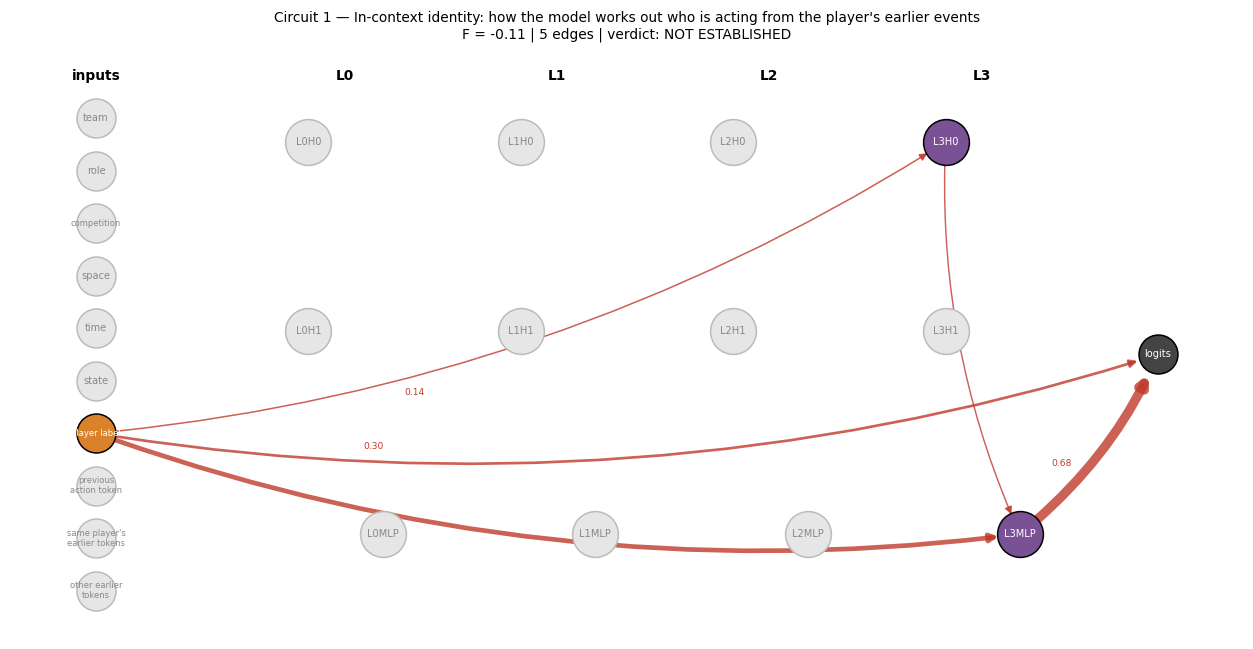

components: ['L3H0', 'L3MLP']
     sender receiver  discovery R     R  CI low  CI high  replicates
      L3MLP   logits        0.673 0.676   0.621    0.724        True
factor_slot    L3MLP        0.221 0.301   0.192    0.427        True
factor_slot   logits        0.129 0.142   0.068    0.205        True
factor_slot   L3H0.q        0.059 0.050   0.015    0.080        True
       L3H0    L3MLP        0.052 0.042   0.004    0.082        True


In [14]:
show('identity')

### Circuit 2 — The previous event: how the model reads what just happened

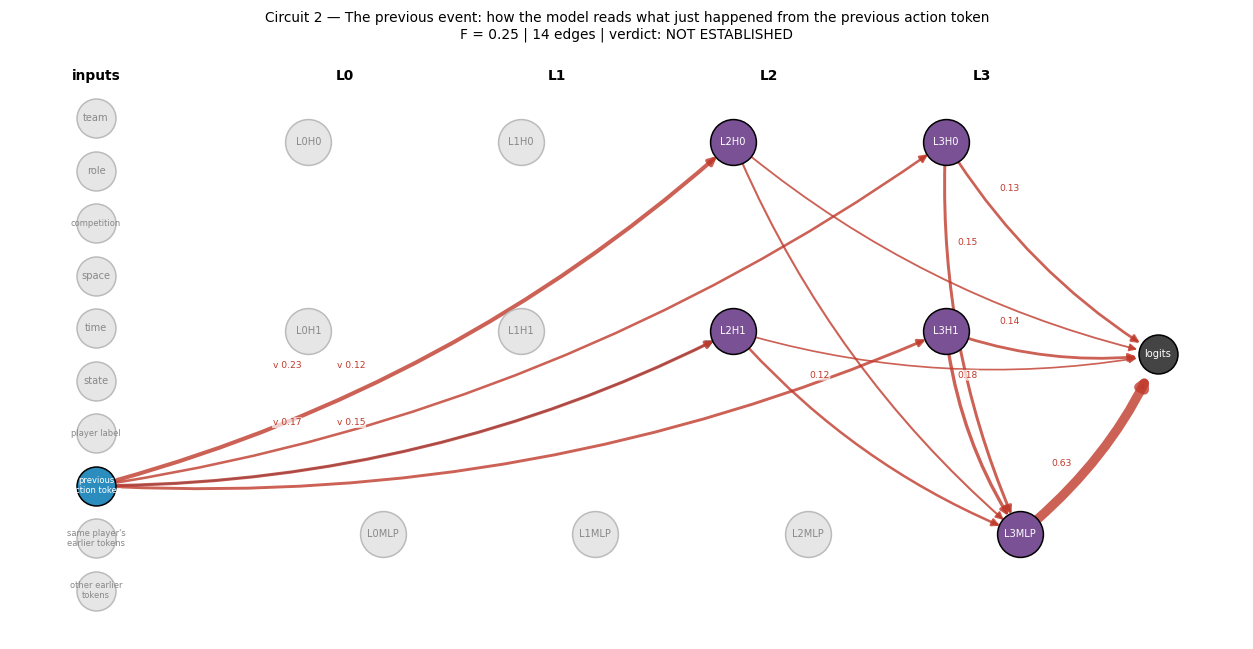

components: ['L2H0', 'L2H1', 'L3H0', 'L3H1', 'L3MLP']
                  sender receiver  discovery R      R  CI low  CI high  replicates
                   L3MLP   logits        0.615  0.628   0.590    0.655        True
previous action token>L2   L2H0.v        0.226  0.235   0.192    0.283        True
                    L3H1    L3MLP        0.169  0.179   0.141    0.210        True
previous action token>L2   L2H1.v        0.101  0.167   0.110    0.212        True
                    L3H0    L3MLP        0.166  0.153   0.116    0.184        True
previous action token>L3   L3H1.v        0.166  0.148   0.126    0.171        True
                    L3H1   logits        0.145  0.141   0.120    0.159        True
                    L3H0   logits        0.160  0.133   0.102    0.162        True
previous action token>L3   L3H0.v        0.188  0.123   0.071    0.169        True
                    L2H1    L3MLP        0.099  0.120   0.098    0.139        True
                    L2H0    L3MLP

In [15]:
show('previous event')

### Circuit 3 — The current situation

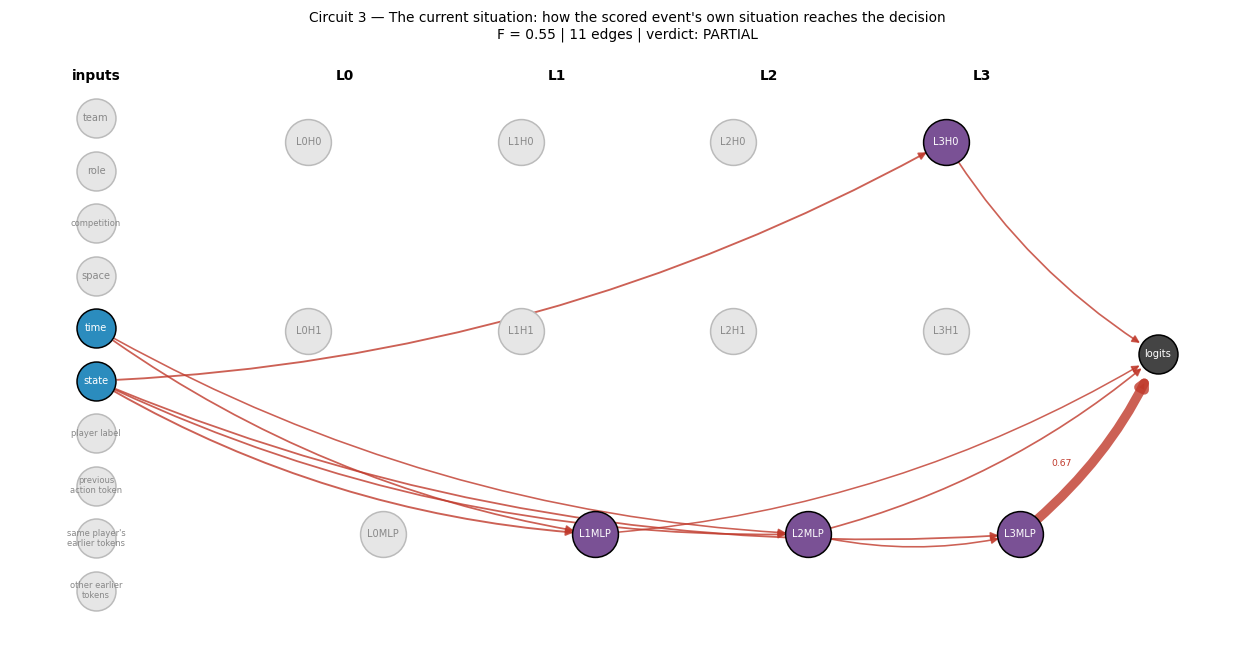

components: ['L1MLP', 'L2MLP', 'L3H0', 'L3MLP']
      sender receiver  discovery R     R  CI low  CI high  replicates
       L3MLP   logits        0.643 0.670   0.642    0.694        True
factor_state    L1MLP        0.078 0.079   0.058    0.101        True
factor_state   L3H0.q        0.068 0.076   0.059    0.089        True
factor_state    L3MLP        0.093 0.069   0.051    0.089        True
factor_state    L2MLP        0.089 0.068   0.047    0.085        True
 factor_time    L1MLP        0.050 0.066   0.023    0.133        True
       L2MLP   logits        0.070 0.063   0.049    0.075        True
        L3H0   logits        0.066 0.061   0.048    0.072        True
 factor_time    L2MLP        0.052 0.056   0.016    0.107        True
       L2MLP    L3MLP        0.058 0.055   0.041    0.077        True
       L1MLP   logits        0.052 0.050   0.041    0.062        True


In [16]:
show('current situation')

### Circuit 4 — Where identity and context meet

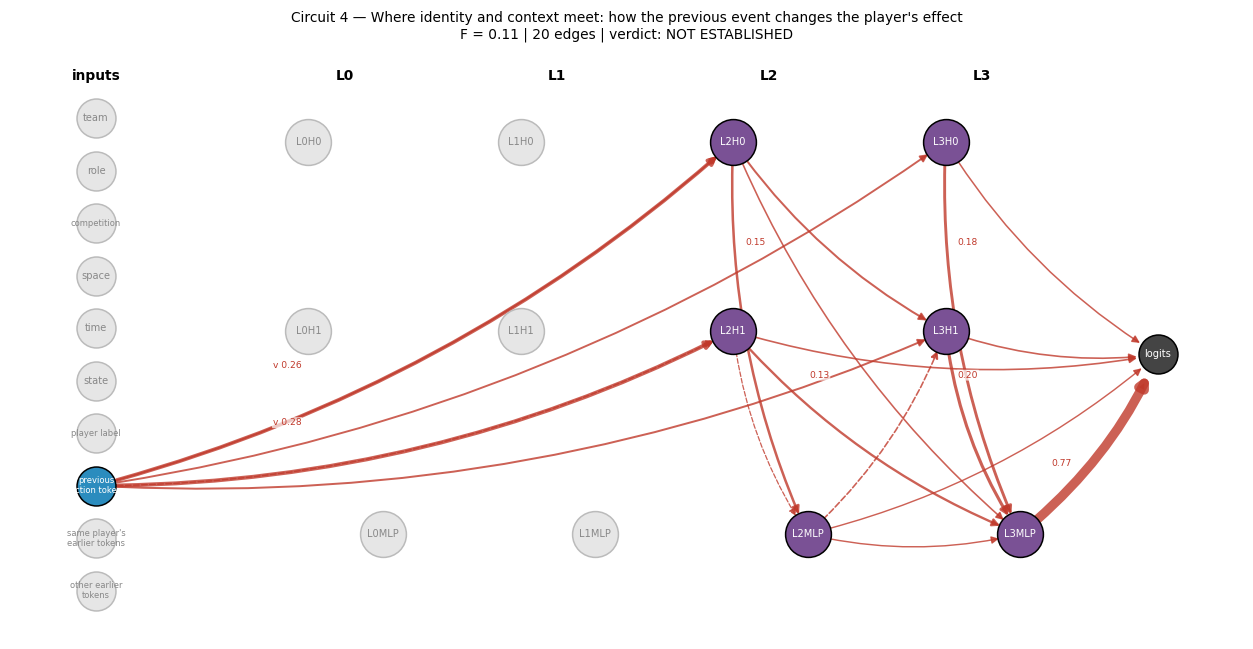

components: ['L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
                  sender receiver  discovery R     R  CI low  CI high  replicates
                   L3MLP   logits        0.759 0.765   0.717    0.817        True
previous action token>L2   L2H1.v        0.244 0.281   0.215    0.346        True
previous action token>L2   L2H0.v        0.270 0.261   0.163    0.387        True
                    L3H1    L3MLP        0.239 0.200   0.123    0.252        True
                    L3H0    L3MLP        0.186 0.180   0.110    0.282        True
                    L2H0    L2MLP        0.139 0.147   0.068    0.202        True
                    L2H1    L3MLP        0.127 0.130   0.077    0.173        True
                    L2H0   L3H1.q        0.060 0.099   0.043    0.173        True
previous action token>L3   L3H1.k        0.055 0.097   0.055    0.139        True
previous action token>L3   L3H0.v        0.104 0.091   0.056    0.131        True
previous action token>L2   L2H0.k  

In [17]:
show('interaction')

### Identity's circuit vs the previous event's circuit

Orange = connection only in the identity circuit, blue = only in the previous-event circuit, purple = in both.

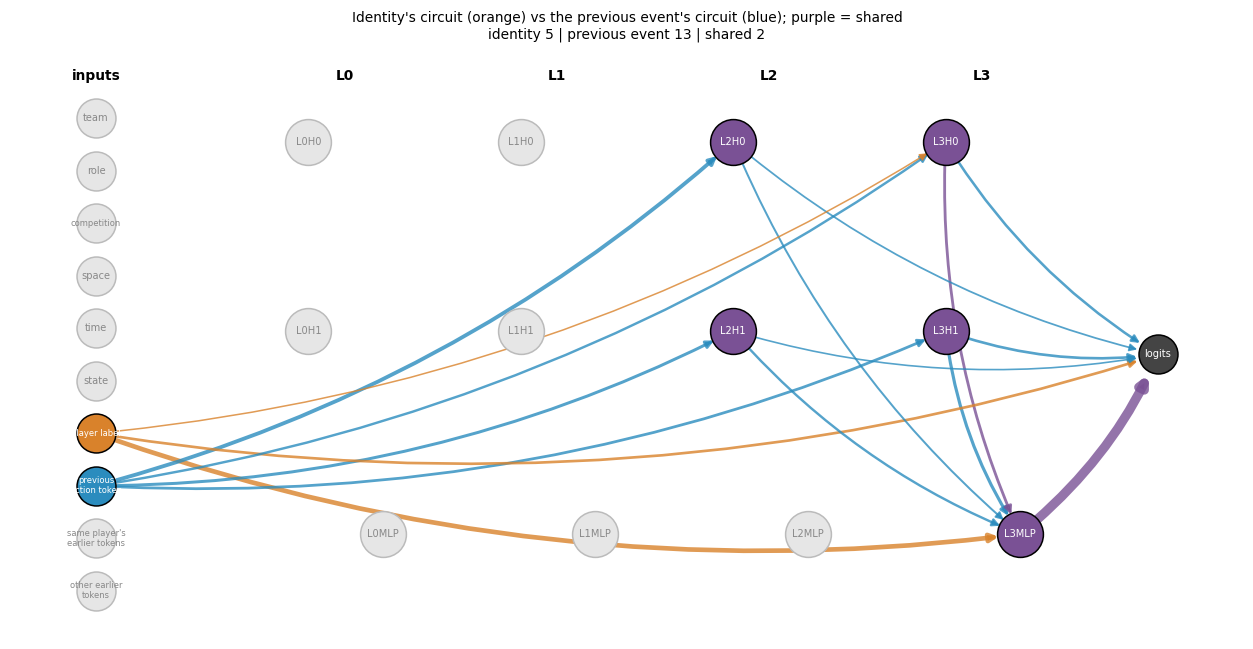

shared: [('L3H0', 'L3MLP'), ('L3MLP', 'logits')]
identity only: [('factor_slot', 'L3H0'), ('factor_slot', 'L3MLP'), ('factor_slot', 'logits')]
previous event only: [('L2H0', 'L3MLP'), ('L2H0', 'logits'), ('L2H1', 'L3MLP'), ('L2H1', 'logits'), ('L3H0', 'logits'), ('L3H1', 'L3MLP'), ('L3H1', 'logits'), ('previous action token', 'L2H0'), ('previous action token', 'L2H1'), ('previous action token', 'L3H0'), ('previous action token', 'L3H1')]


In [18]:
pairs = lambda name: {(node_of(s), node_of(r)) for s, r in zip(ATLAS[name]["estimation"]["sender"], ATLAS[name]["estimation"]["receiver"])}
id_pairs, prev_pairs = pairs("identity"), pairs("previous event")
combined = pd.concat([ATLAS["identity"]["estimation"], ATLAS["previous event"]["estimation"]], ignore_index=True)
if len(combined):
    combined["pair"] = [(node_of(s), node_of(r)) for s, r in zip(combined["sender"], combined["receiver"])]
    combined = combined.sort_values("R", key=np.abs, ascending=False).drop_duplicates("pair")
fig, axis = plt.subplots(figsize=(11.5, 6))
draw(axis, combined, f"Identity's circuit (orange) vs the previous event's circuit (blue); purple = shared\n"
                     f"identity {len(id_pairs)} | previous event {len(prev_pairs)} | shared {len(id_pairs & prev_pairs)}",
     colour_of=lambda row: "#7a5195" if (row["pair"] in id_pairs and row["pair"] in prev_pairs) else ("#d9822b" if row["pair"] in id_pairs else "#2b8cbe"),
     labels=False)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB23_identity_vs_previous_event.png", bbox_inches="tight", dpi=150); plt.show()
print("shared:", sorted(id_pairs & prev_pairs)); print("identity only:", sorted(id_pairs - prev_pairs)); print("previous event only:", sorted(prev_pairs - id_pairs))

## 9. SEL-4L vs the two-token model, side by side

| Question | SEL-4L (MB14–MB19) | Two-token, anonymous identity (this notebook) |
|---|---|---|
| Heads alone keep | see regenerated MB14 | see Section 6 |
| MLPs alone keep | see regenerated MB14 | see Section 6 |
| Identity reaches the decision through | the player embedding at the scored event, then the MLP chain | see Circuit 1 |
| Previous event reaches the decision through | the scored event's own history fields, then the MLP chain | see Circuit 2 |
| Identity and context meet in | the MLP chain (non-linearity, not specific to the player) | see Circuit 4 |

In [19]:
summary = {"status": PLAN["status"], "behaviour": behaviour.to_dict(orient="records"), "attention": attention.to_dict(orient="records"),
           "heads_vs_mlps": named_tt.to_dict(orient="records"), "shapley": shapley_tt.reset_index().to_dict(orient="records"),
           "circuits": verdicts_tt.to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB23_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB23_summary.json": OUT / "results" / "MB23_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB23", "experiment": "two-token model: behaviour, attention, subsets, circuits", "run_mode": RUN_MODE})
print(named_tt[["behaviour", "F: all heads, no MLP", "F: all MLPs, no head", "attention USED (plan rule)"]].round(3).to_string(index=False))

        behaviour  F: all heads, no MLP  F: all MLPs, no head  attention USED (plan rule)
         identity                 0.043                 0.512                        True
   previous event                 0.198                 0.000                        True
current situation                 0.068                 0.638                        True
      interaction                 0.049                 0.000                        True


In [20]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 111
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label: